# A tour of `lefsim`

`lefsim` simulates loop-extrusion factors (LEFs) on a 1D lattice with CTCF
boundary elements, using an exact event-driven (Gibson–Bruck) engine written in
Rust. From Python, results arrive as **Arrow** data, so they drop straight into
polars, pyarrow, pandas or duckdb, and long runs can be **streamed** instead of
held in memory.

This notebook builds a lattice with a few TADs, runs it, and looks at the
result from several angles: leg trajectories, a ChIP-like occupancy profile,
where loops are anchored, loop sizes, the event log, and a streamed run far too
large to materialize. It ends with saving a model, replaying a recorded run,
and branching a new run from a replayed state.

**Running it.** From `crates/lefsim-py`:

```
uv venv && uv pip install maturin ipykernel matplotlib polars pyarrow duckdb
maturin develop --uv --release
```

then pick that `.venv` as the notebook kernel.

In [1]:
import time

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.colors import LinearSegmentedColormap, LogNorm

import lefsim

# Plot styling: quiet chrome, one blue for "all", orange for emphasis,
# and a single-hue blue ramp for magnitudes.
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": MUTED, "ytick.labelcolor": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK2,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "figure.dpi": 110,
})
print("lefsim", lefsim.__version__)

lefsim 0.1.0


## 1. A model: lattice, world, rates

A model has three parts:

- a **`Lattice`**: 3,000 sites split into five TADs by four boundaries. Each
  boundary is a **convergent CTCF pair**: the site ending the TAD on its left
  captures legs arriving from the left, and the next site, starting the TAD on
  its right, captures legs arriving from the right. A leg that slips through the
  first CTCF (probability 1 − strength) meets the second one from its eviction
  side.
- a **`World`**: the LEFs on the lattice. `populate` places twenty of them the
  way respawns do, at random non-CTCF sites, with its own seed.
- the **`Rates`**: a step rate, and four respawn (unloading) rates. A LEF
  unloads at the first that applies: `respawn_captured` if either leg is
  captured (here 5× slower than basal, so held loops last), `respawn_evicted`
  if either leg is evicted (here fast), `respawn_stalled` if either leg is
  blocked by another leg or the lattice's end (here equal to basal, so traffic
  doesn't change lifetimes), else the basal `respawn`.

A leg meeting a CTCF from its non-capture side is **evicted** with probability
`strength` (for certain if a captured leg already holds that CTCF): the step
doesn't happen, and the leg waits where it is for its LEF to unload.

In [2]:
N_SITES = 3_000
BOUNDARIES = [600, 1300, 1800, 2500]

ctcf_sites, ctcf_sides = [], []
for b in BOUNDARIES:
    ctcf_sites += [b, b + 1]
    ctcf_sides += ["left", "right"]

lattice = lefsim.Lattice(N_SITES, {"site": ctcf_sites, "captures_from": ctcf_sides, "strength": 0.8})
world = lefsim.populate(lattice, 20, seed=1)
rates = lefsim.Rates(step=1.0, respawn=0.002, respawn_stalled=0.002, respawn_evicted=0.2, respawn_captured=0.0004)
model = lefsim.Model(world, rates)
model

lefsim.Model(n_sites=3000, n_lefs=20, Rates(step=1.0, respawn=0.002, respawn_stalled=0.002, respawn_evicted=0.2, respawn_captured=0.0004), spawn_rule="uniform_non_ctcf")

Each part reads back as a table. The lattice is its CTCF list (the size is
in the schema metadata); the world is one row per LEF.

In [3]:
pl.DataFrame(lattice.to_arrow())

site,captures_from,strength
u32,cat,f64
600,"""Left""",0.8
601,"""Right""",0.8
1300,"""Left""",0.8
1301,"""Right""",0.8
1800,"""Left""",0.8
1801,"""Right""",0.8
2500,"""Left""",0.8
2501,"""Right""",0.8


In [4]:
pl.DataFrame(world.to_arrow()).head()

lef_id,left_pos,right_pos,left_mobility,right_mobility
u32,u32,u32,cat,cat
0,422,422,"""Moving""","""Moving"""
1,856,856,"""Moving""","""Moving"""
2,2018,2018,"""Moving""","""Moving"""
3,2771,2771,"""Moving""","""Moving"""
4,1020,1020,"""Moving""","""Moving"""


A world can also be written by hand, from any table with `left_pos` and
`right_pos` columns (and optionally `left_mobility` / `right_mobility`). Every
LEF is checked: legs on the lattice, no two LEFs on one site, a captured leg
only on a CTCF that could have captured it, and an evicted leg only just before
a CTCF it met from behind.

In [5]:
lefsim.World(lattice, {"left_pos": [100, 1301], "right_pos": [140, 1500], "left_mobility": ["moving", "captured"]})

lefsim.World(n_sites=3000, n_lefs=2)

In [6]:
try:
    lefsim.World(lattice, {"left_pos": [600], "right_pos": [640], "left_mobility": ["captured"]})
except ValueError as e:
    print(e)

LEF 0: a left-facing leg can't be captured by the CTCF at 600, which captures from the left


## 2. Run and record

A `Sim` runs a model from a seed. `run_*` methods only advance the run;
`record_*` methods advance it and return what happened. With `dt=`,
`record_until` takes a snapshot of every LEF on a regular time grid. Snapshots
are exact, not interpolated, because state only changes at events. With
`events=True` it also logs every state change. The run releases the GIL and
responds to Ctrl-C.

In [7]:
sim = lefsim.Sim(model, seed=1)

t = time.perf_counter()
rec = sim.record_until(50_000.0, dt=5.0, events=True)
elapsed = time.perf_counter() - t
print(f"{rec.n_events:,} events in {elapsed:.2f} s ({rec.n_events / elapsed / 1e6:.1f} M events/s)")
rec

382,101 events in 0.07 s (5.7 M events/s)


lefsim.Recording(n_events=382101, time=50000.0, stopped="reached_time", snapshots=200020, events=383507)

`rec.snapshots` is an Arrow batch; `pl.DataFrame` reads it without copying.
Each snapshot is the world's LEF table plus a `time` column: one row per LEF,
with both legs side by side. Mobility columns are categorical.

In [8]:
m = sim.model()

import json
with open("model.json", "wt") as f:
    json.dump(m.to_dict(), f, indent=2)

In [9]:
snaps = pl.DataFrame(rec.snapshots)
events = pl.DataFrame(rec.events)
snaps.head()

time,lef_id,left_pos,right_pos,left_mobility,right_mobility
f64,u32,u32,u32,cat,cat
0.0,0,422,422,"""Moving""","""Moving"""
0.0,1,856,856,"""Moving""","""Moving"""
0.0,2,2018,2018,"""Moving""","""Moving"""
0.0,3,2771,2771,"""Moving""","""Moving"""
0.0,4,1020,1020,"""Moving""","""Moving"""


Rows are ordered by snapshot, then `lef_id`, so any column reshapes to a
`(n_snapshots, n_lefs)` array:

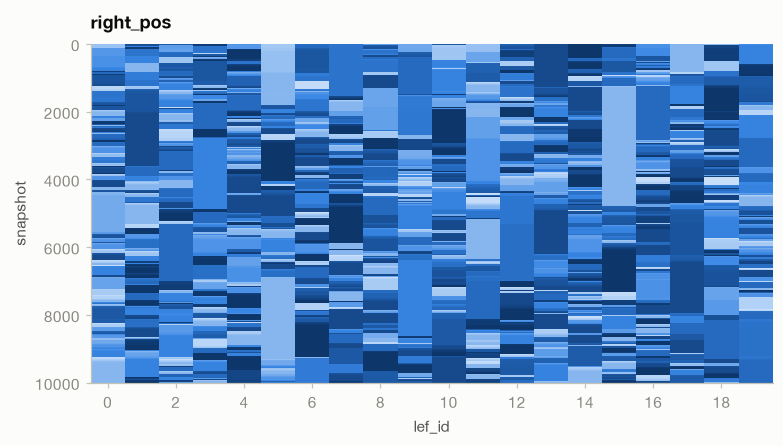

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.imshow(snaps["right_pos"].to_numpy().reshape(-1, sim.n_lefs), aspect="auto", cmap=BLUES, interpolation="nearest")
ax.set(xlabel="lef_id", ylabel="snapshot", title="right_pos", xticks=range(0, sim.n_lefs, 2))
ax.grid(False)
plt.show()

## 3. Leg trajectories

Each leg's position over a 4,000-unit window. Pairs of legs fan out from their
binding site, then run flat once a boundary holds them. One LEF is highlighted
from the moment it binds until both of its legs are held at a TAD's CTCFs.

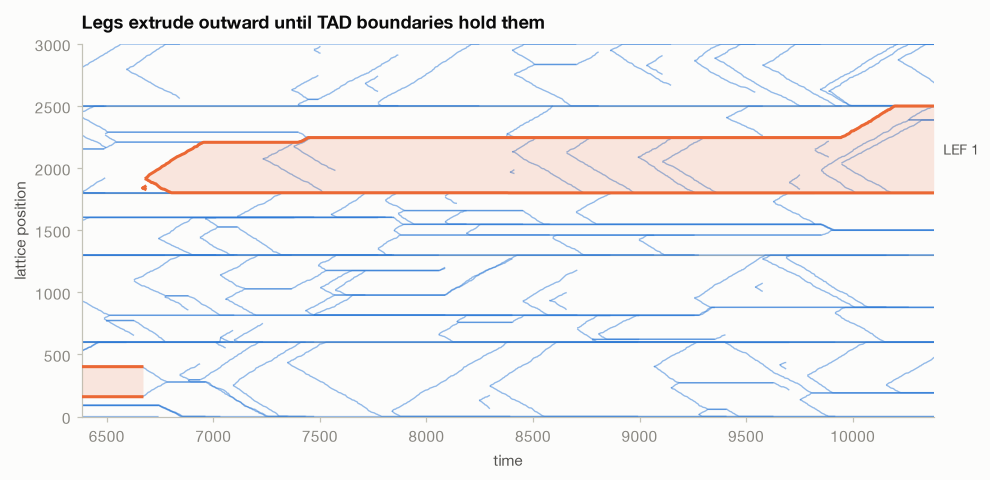

In [11]:
# Find the binding (a Respawn) that ends with both legs captured for longest,
# and center a window on it.
fully_held = snaps.filter((pl.col("left_mobility") == "Captured") & (pl.col("right_mobility") == "Captured"))
respawns = events.filter(pl.col("action") == "Respawn").unique(["time", "lef_id"]).sort("time")
best = (None, None, 0)
for lef, t_bind in respawns.select("lef_id", "time").iter_rows():
    t_next = respawns.filter((pl.col("lef_id") == lef) & (pl.col("time") > t_bind))["time"].min() or rec.time
    n_held = fully_held.filter((pl.col("lef_id") == lef) & pl.col("time").is_between(t_bind, t_next)).height
    if n_held > best[2]:
        best = (lef, t_bind, n_held)
focus, t_bind, _ = best

T0 = round(t_bind) - 300
T1 = T0 + 4_000
window = snaps.filter(pl.col("time").is_between(T0, T1))

def broken(t, x, jump=40):
    # Break the line where a leg jumps (a respawn) instead of drawing a vertical stroke.
    t, x = np.asarray(t, float), np.asarray(x, float)
    cut = np.flatnonzero(np.abs(np.diff(x)) > jump) + 1
    return np.insert(t, cut, np.nan), np.insert(x, cut, np.nan)

fig, ax = plt.subplots(figsize=(10, 4.4))
for b in BOUNDARIES:
    ax.axhline(b + 0.5, color=AXIS, lw=0.8, zorder=1)
for (lef,), g in window.group_by("lef_id", maintain_order=True):
    hl = lef == focus
    for col in ("left_pos", "right_pos"):
        ax.plot(*broken(g["time"], g[col]), color=ORANGE if hl else BLUE,
                lw=2 if hl else 0.9, alpha=1 if hl else 0.5, zorder=4 if hl else 2)
g = window.filter(pl.col("lef_id") == focus)
ax.fill_between(g["time"], g["left_pos"], g["right_pos"], step="post", color=ORANGE, alpha=0.15, lw=0, zorder=3)
ax.annotate(f"LEF {focus}", (T1, (g["left_pos"][-1] + g["right_pos"][-1]) / 2), xytext=(6, 0),
            textcoords="offset points", color=INK2, va="center", fontsize=9, annotation_clip=False)
ax.set(xlim=(T0, T1), ylim=(0, N_SITES), xlabel="time", ylabel="lattice position")
ax.set_title("Legs extrude outward until TAD boundaries hold them")
ax.grid(False)
plt.show()

## 4. Leg occupancy

Averaging leg positions over the run (after a short burn-in) gives a
profile like cohesin ChIP-seq: sharp accumulation at the CTCF pairs (marked
◀▶, pointing toward the side each one captures from), and at the lattice ends,
where legs simply stop.

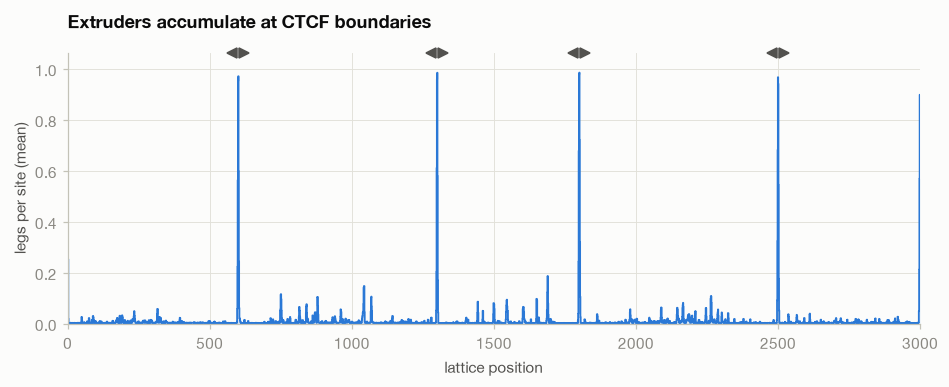

In [12]:
from matplotlib.transforms import offset_copy

BURN_IN = 5_000
settled = snaps.filter(pl.col("time") >= BURN_IN)
n_snapshots = settled["time"].n_unique()
legs = np.concatenate([settled["left_pos"].to_numpy(), settled["right_pos"].to_numpy()])
occupancy = np.bincount(legs, minlength=N_SITES) / n_snapshots

def mark_ctcfs(ax, y, gap=4):
    lo, hi = ax.get_xlim()
    for site, side in zip(ctcf_sites, ctcf_sides):
        if lo <= site <= hi:
            dx = -gap if side == "left" else gap
            shift = offset_copy(ax.transData, fig=ax.figure, x=dx, y=0, units="points")
            ax.plot(site, y, marker="<" if side == "left" else ">", color=INK2, ms=6,
                    clip_on=False, zorder=5, transform=shift)

fig, ax = plt.subplots(figsize=(10, 3.2))
x = np.arange(N_SITES)
ax.fill_between(x, occupancy, step="mid", color=BLUE, alpha=0.18, lw=0)
ax.step(x, occupancy, where="mid", color=BLUE, lw=1.2)
top = occupancy.max() * 1.08
ax.set(xlim=(0, N_SITES), ylim=(0, top), xlabel="lattice position", ylabel="legs per site (mean)")
mark_ctcfs(ax, top)
ax.set_title("Extruders accumulate at CTCF boundaries", pad=16);

## 5. Where cohesin bridges

Every snapshot gives each LEF's loop as a pair `(left anchor, right anchor)`.
A 2D histogram of those pairs (log color) shows three things:

- **Insulation.** Almost no loops span a boundary; mass stays inside the TAD triangles.
- **Stripes.** The dark top edge of each triangle is loops with the right leg
  held at the boundary while the left leg keeps extruding, the model's
  analogue of Hi-C stripes.
- **Corners.** Where the two edges meet, both legs are held: a whole-TAD loop.

This is cohesin bridging, not a contact map. It is what a contact map's dots and
stripes would be built from.

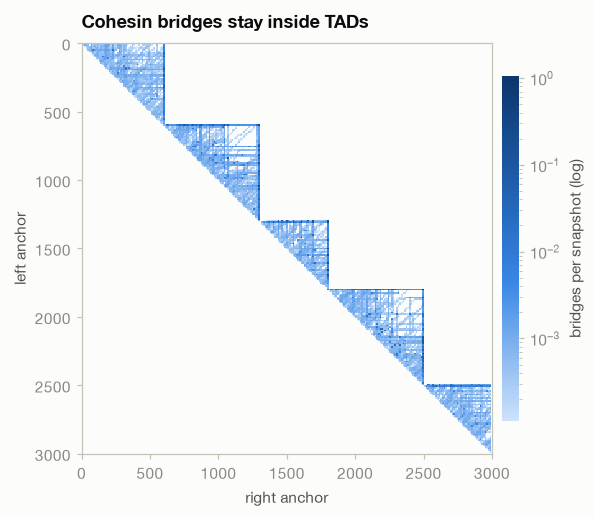

In [13]:
binsize = 12
bins = np.arange(-binsize/2, N_SITES + binsize/2, binsize)
H, _, _ = np.histogram2d(settled["left_pos"].to_numpy(), settled["right_pos"].to_numpy(), bins=[bins, bins])
H = np.ma.masked_where(H == 0, H) / n_snapshots

fig, ax = plt.subplots(figsize=(5.8, 5.1))
im = ax.pcolormesh(bins, bins, H, cmap=BLUES, norm=LogNorm(), rasterized=True)
ax.set(xlim=(0, N_SITES), ylim=(N_SITES, 0), aspect="equal", xlabel="right anchor", ylabel="left anchor")
ax.spines["right"].set_visible(True)
ax.spines["top"].set_visible(True)
ax.grid(False)

cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
cb.set_label("bridges per snapshot (log)", color=INK2)
cb.outline.set_visible(False)
cb.ax.tick_params(colors=AXIS, labelcolor=MUTED)

ax.set_title("Cohesin bridges stay inside TADs");

## 6. Loop sizes

Loops that are still growing have a broad size distribution. Once a boundary
holds one leg, sizes pile up at the **full TAD sizes** as the other leg reaches
the opposite boundary.

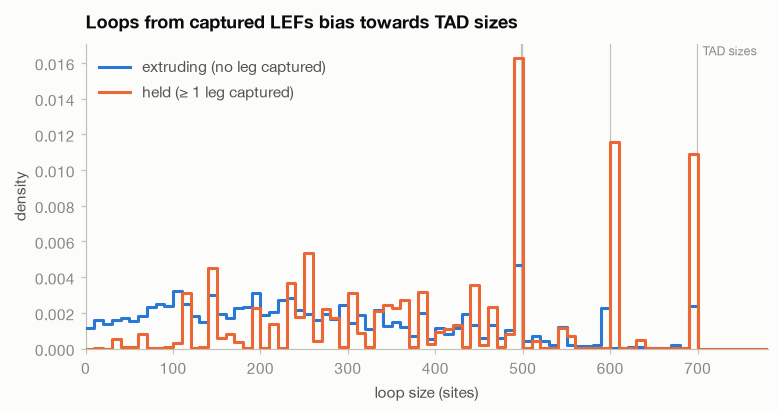

In [14]:
settled = settled.with_columns(
    size=pl.col("right_pos").cast(pl.Int64) - pl.col("left_pos").cast(pl.Int64),
    held=(pl.col("left_mobility") == "Captured") | (pl.col("right_mobility") == "Captured"),
)
tad_edges = [0] + [b + 1 for b in BOUNDARIES], BOUNDARIES + [N_SITES - 1]
tad_sizes = sorted({hi - lo for lo, hi in zip(*tad_edges)})

fig, ax = plt.subplots(figsize=(8, 3.6))
binsize = 10
edges = np.arange(0, 800, binsize)
for s in tad_sizes:
    ax.axvline(s, color=AXIS, lw=0.8, zorder=1)

ax.text(tad_sizes[-1], 1.0, "  TAD sizes", transform=ax.get_xaxis_transform(), color=MUTED, fontsize=8, va="top")

for held, color, label in [(False, BLUE, "extruding (no leg captured)"), (True, ORANGE, "held (≥ 1 leg captured)")]:
    h, _ = np.histogram(settled.filter(pl.col("held") == held)["size"], bins=edges, density=True)
    ax.step(edges[:-1], h, where="post", color=color, lw=2, label=label, zorder=3)

ax.set(xlim=(0, 780), ylim=(0, None), xlabel="loop size (sites)", ylabel="density")
ax.legend(loc="upper left")
ax.grid(False)
ax.set_title("Loops from captured LEFs bias towards TAD sizes");

## 7. The event log

`events=True` records one row per leg changed by each event: a `Step` moves one
leg, and a `Respawn` places both. `mobility` is the leg's state *after* the
event, so capture and eviction counts come from a single group-by.

In [15]:
events.head()

time,leg_id,lef_id,pos,mobility,action
f64,u32,u32,u32,cat,cat
0.01713,3,1,857,"""Moving""","""Step"""
0.036011,29,14,2928,"""Moving""","""Step"""
0.053459,3,1,858,"""Moving""","""Step"""
0.087905,26,13,2480,"""Moving""","""Step"""
0.118338,4,2,2017,"""Moving""","""Step"""


In [16]:
(
    events.group_by("action", "mobility")
    .len()
    .sort("action", "mobility")
)

action,mobility,len
cat,cat,u32
"""Respawn""","""Moving""",2812
"""Step""","""Captured""",128
"""Step""","""Evicted""",31
"""Step""","""Moving""",380536


An evicted leg doesn't step onto the CTCF that turned it back: it waits on the
site just before it until its LEF unloads. At a convergent pair, that site is
the pair's other CTCF: a right-facing leg that slips past the left CTCF of a
boundary (at `b`) is evicted by the right one (at `b + 1`) and waits at `b`, and
a left-facing leg the reverse, at `b + 1`.

Most of the evicted legs the snapshots catch belong to LEFs whose *other* leg is
captured. Capture takes precedence over eviction, so such a LEF unloads at the
slow `respawn_captured` and its evicted leg waits long. With both legs otherwise
free, a LEF unloads at `respawn_evicted` within a few time units.

In [17]:
evicted = pl.concat([
    snaps.filter(pl.col("left_mobility") == "Evicted").select(side=pl.lit("left"), pos="left_pos", other="right_mobility"),
    snaps.filter(pl.col("right_mobility") == "Evicted").select(side=pl.lit("right"), pos="right_pos", other="left_mobility"),
])
print(f"evicted legs in {snaps['time'].n_unique():,} snapshots: {evicted.height:,}")
print("by the other leg's state:", dict(evicted.group_by("other").len().iter_rows()))
evicted.group_by("side", "pos").len().sort("pos")

evicted legs in 10,001 snapshots: 1,043
by the other leg's state: {'Captured': 1019, 'Moving': 24}


side,pos,len
str,u32,u32
"""right""",600,1
"""left""",601,678
"""right""",1300,79
"""left""",1301,107
"""right""",1800,159
"""left""",1801,14
"""right""",2500,2
"""left""",2501,3


The current state is always one call away. `sim.state()` gives one row per
LEF (or per leg with `layout="leg"`, the event log's row shape, convenient for
per-leg group-bys), and
`sim.model()` returns it as a new `Model`.

In [18]:
pl.DataFrame(sim.state(layout="leg")).head(6)

time,leg_id,lef_id,pos,mobility
f64,u32,u32,u32,cat
50000.0,0,0,0,"""Moving"""
50000.0,1,0,600,"""Captured"""
50000.0,2,1,2700,"""Moving"""
50000.0,3,1,2999,"""Moving"""
50000.0,4,2,713,"""Moving"""
50000.0,5,2,939,"""Moving"""


## 8. Streaming a long run

The occupancy profile above is noisy at single-site resolution. For finer
statistics we want a much longer run: **2 million time units**, sampled every
time unit, is ~80 million leg-rows (~1.7 GB if materialized).

`sim.stream(...)` hands the simulation to a lazy Arrow stream that runs *as it
is read*, one chunk at a time. duckdb aggregates it on the fly, so memory stays
bounded. (A stream consumes its `Sim`, so we start a fresh one from the same model.)

In [19]:
long_sim = lefsim.Sim(model, seed=2)
stream = long_sim.stream(2_000_000.0, dt=1.0, layout="leg", max_snapshots=50_000)

t = time.perf_counter()
per_site = duckdb.sql(f'''
    select pos, count(*) as n
    from stream
    where time >= {BURN_IN}
    group by pos
''').pl()
elapsed = time.perf_counter() - t

rows = per_site["n"].sum()
print(f"aggregated {rows:,} leg-rows (~{rows * 21 / 1e9:.1f} GB if materialized) in {elapsed:.1f} s")

aggregated 79,800,040 leg-rows (~1.7 GB if materialized) in 3.1 s


In [20]:
n_long = rows // (2 * model.world.n_lefs)  # snapshots after burn-in
occupancy_long = np.zeros(N_SITES)
occupancy_long[per_site["pos"].to_numpy()] = per_site["n"].to_numpy() / n_long

cv = lambda a: a.std() / a.mean()
print(f"TAD interior (sites 620-1280), coefficient of variation: "
      f"{cv(occupancy[620:1280]):.2f} in memory -> {cv(occupancy_long[620:1280]):.2f} streamed")

TAD interior (sites 620-1280), coefficient of variation: 1.95 in memory -> 0.47 streamed


Zooming in on one boundary (sites 1300/1301), on a log scale. The peak is big
enough to see even in the short run; the long run pins down its tails and the
flanks around it.

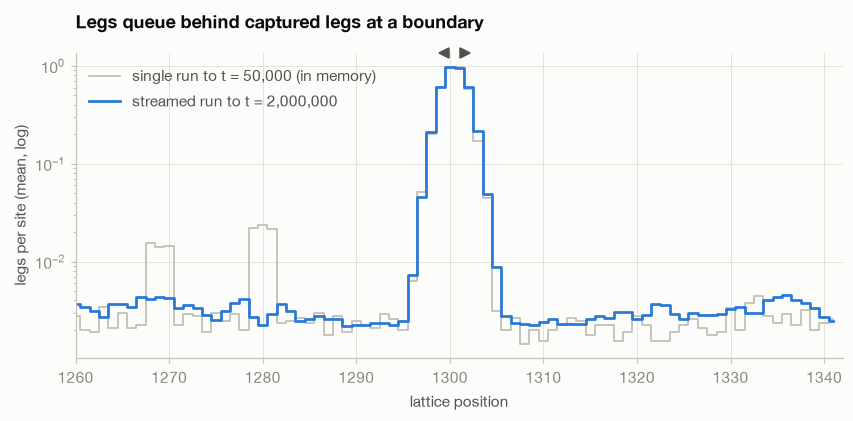

sites 1296-1305 (streamed): [0.007 0.046 0.209 0.602 0.964 0.958 0.605 0.218 0.049 0.009]


In [21]:
lo, hi = 1260, 1342
x = np.arange(lo, hi)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.step(x, np.where(occupancy[lo:hi] > 0, occupancy[lo:hi], np.nan), where="mid",
        color=AXIS, lw=1.2, label="single run to t = 50,000 (in memory)")
ax.step(x, occupancy_long[lo:hi], where="mid", color=BLUE, lw=1.8, label="streamed run to t = 2,000,000")
ax.set_yscale("log")
ax.set(xlim=(lo, hi), xlabel="lattice position", ylabel="legs per site (mean, log)")
mark_ctcfs(ax, ax.get_ylim()[1])
ax.legend(loc="upper left")
ax.set_title("Legs queue behind captured legs at a boundary", pad=16)
plt.show()

print("sites 1296-1305 (streamed):", np.round(occupancy_long[1296:1306], 3))

The boundary peak is a **queue**: occupancy falls off steeply on both sides of
the CTCF pair (about 0.96 → 0.6 → 0.2 → 0.05 per site), because legs pile up
behind a captured leg and can't step onto an occupied site. Just past the
queue, occupancy (~0.0025 per site) is well under half its value ~100 sites
deeper into the TAD (~0.006). With ~220× more snapshots, the interior noise also drops
(the coefficient of variation above).

To keep the raw data instead, stream to Parquet the same way:
`duckdb.sql("copy (select * from stream) to 'run.parquet'")`.

## 9. Save, replay, branch

A model saves as a small versioned JSON document and loads back through the
same checks as building it in code. `sim.model()` does the same for the state
mid-run.

In [22]:
doc = sim.model().to_json(indent=1)
print(doc[:400], "...")
assert lefsim.Model.from_json(doc) == sim.model()

{
 "format": "lefsim.model",
 "version": 2,
 "lattice": {
  "n_sites": 3000,
  "ctcfs": [
   {
    "site": 600,
    "captures_from": "left",
    "strength": 0.8
   },
   {
    "site": 601,
    "captures_from": "right",
    "strength": 0.8
   },
   {
    "site": 1300,
    "captures_from": "left",
    "strength": 0.8
   },
   {
    "site": 1301,
    "captures_from": "right",
    "strength": 0.8
   } ...


A keyframed event log (`events=True, keyframes=True`) is a compact, lossless
record of a run: every batch opens with the full state, so the log can be
replayed from any batch. Here a run is streamed to Parquet, and a `Replayer`
reads it back and rebuilds the state at any time, without simulating.

In [23]:
import pathlib, tempfile
import pyarrow.parquet as pq

path = pathlib.Path(tempfile.mkdtemp()) / "run.parquet"
T_END = 20_000.0
stream = lefsim.Sim(model, seed=3).stream(T_END, events=True, keyframes=True, max_rows=20_000)
duckdb.sql(f"copy (select * from stream) to '{path}'")
print(f"{pq.ParquetFile(path).metadata.num_rows:,} event rows, {path.stat().st_size / 1e6:.1f} MB")

replayer = lefsim.Replayer.from_arrow(pq.ParquetFile(path).iter_batches(), lattice, end=T_END)
replayer

150,335 event rows, 1.7 MB


lefsim.Replayer(n_lefs=20, start=0.0, end=20000.0, time=-inf)

The replayed state at any time equals the live run's, and `snapshots(dt)`
decodes the log to the same grid table `record_until(dt=...)` would have
recorded.

In [24]:
live = lefsim.Sim(model, seed=3)
live.run_until(12_345.6)
assert replayer.world_at(12_345.6) == live.world()

grid = pl.DataFrame(replayer.snapshots(100.0, t_start=0.0))
recorded = pl.DataFrame(lefsim.Sim(model, seed=3).record_until(T_END, dt=100.0).snapshots)
print("decoded grid equals the recorded one:", grid.equals(recorded))

decoded grid equals the recorded one: True


**Branching.** A replayed world is a valid starting state. Runs started from
it with new seeds continue the original faithfully in distribution (the dynamics
are memoryless), though not event for event. Here eight branches from t = 10,000
spread out from the recorded trajectory of one LEF's legs.

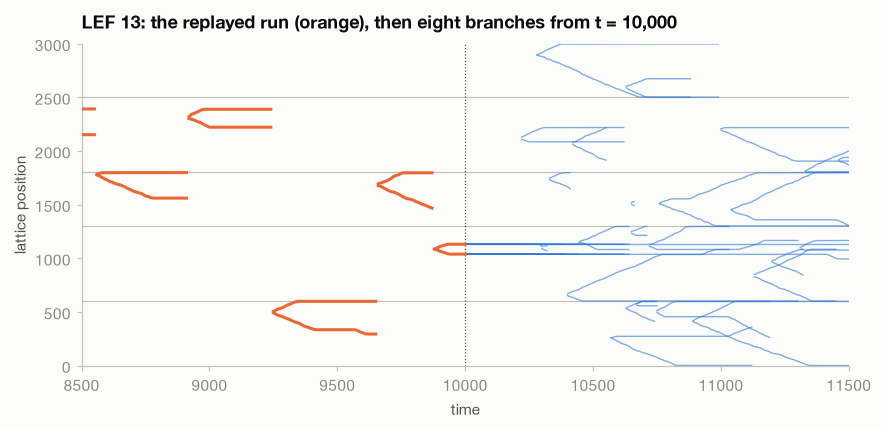

In [25]:
T_BRANCH, SPAN = 10_000.0, 1_500.0
replayer.seek(T_BRANCH)
at_branch = pl.DataFrame(replayer.state())
# Follow the most recently bound LEF (the smallest loop with both legs free),
# so the branches visibly extrude.
lef = (
    at_branch.filter((pl.col("left_mobility") == "Moving") & (pl.col("right_mobility") == "Moving"))
    .with_columns(span=pl.col("right_pos").cast(pl.Int64) - pl.col("left_pos").cast(pl.Int64))
    .sort("span")["lef_id"][0]
)
branch_model = lefsim.Model(replayer.world(), rates)

fig, ax = plt.subplots(figsize=(9, 3.8))
for bd in BOUNDARIES:
    ax.axhline(bd + 0.5, color=AXIS, lw=0.8, zorder=1)
for seed in range(8):
    b = lefsim.Sim(branch_model, seed=100 + seed, start_time=T_BRANCH)
    s = pl.DataFrame(b.record_until(T_BRANCH + SPAN, dt=10.0).snapshots).filter(pl.col("lef_id") == lef)
    for col in ("left_pos", "right_pos"):
        ax.plot(*broken(s["time"], s[col]), color=BLUE, lw=0.9, alpha=0.6, zorder=2)
past = pl.DataFrame(replayer.snapshots(10.0, t_start=T_BRANCH - SPAN, t_end=T_BRANCH)).filter(pl.col("lef_id") == lef)
for col in ("left_pos", "right_pos"):
    ax.plot(*broken(past["time"], past[col]), color=ORANGE, lw=2, zorder=3)
ax.axvline(T_BRANCH, color=INK2, lw=0.8, ls=":")
ax.set(xlim=(T_BRANCH - SPAN, T_BRANCH + SPAN), ylim=(0, N_SITES), xlabel="time", ylabel="lattice position")
ax.set_title(f"LEF {lef}: the replayed run (orange), then eight branches from t = 10,000")
ax.grid(False)
plt.show()

`copy.copy(sim)` is the exact version: a fork of a live run that continues
event for event as the original would.

In [26]:
import copy
fork = copy.copy(sim)
print("fork matches the original:",
      pl.DataFrame(sim.record_until(sim.time + 500, dt=5.0).snapshots).equals(
      pl.DataFrame(fork.record_until(fork.time + 500, dt=5.0).snapshots)))

fork matches the original: True


## 10. Reproducibility

A model and a seed fix the whole run, bit for bit. That holds across Python and
Rust, and across native and WebAssembly builds. The test suites pin a golden
hash of a long run in all three languages.

In [27]:
def run(seed):
    s = lefsim.Sim(model, seed=seed)
    return pl.DataFrame(s.record_until(5_000.0, dt=1.0).snapshots)

print("same seed, identical:", run(7).equals(run(7)))
print("different seed, identical:", run(7).equals(run(8)))

same seed, identical: True
different seed, identical: False
